# Notebook 04 – Learning curve, bias–variance bằng bootstrap, phân tích lỗi và mức ảnh hưởng của đặc trưng
Tiếp nối notebook 03: cùng tập huấn luyện, cùng 5 fold, cùng đặc trưng đa thức (`weight`, `horsepower`, `acceleration`, `model_year` + `origin`).
Tập kiểm tra 80 mẫu vẫn **không được dùng**. Chạy notebook từ thư mục `notebooks/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import learning_curve, cross_val_predict
from sklearn.pipeline import make_pipeline

from data import NUM, CAT, TARGET, SEED, split
from preprocess import build_preprocessor
from evaluate import cv_folds

warnings.filterwarnings("ignore", category=RuntimeWarning)
FIG, REP = Path("../reports/figures"), Path("../reports")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

train, test = split()
y = train[TARGET]
folds = cv_folds(train)
POLY = ["weight", "horsepower", "acceleration", "model_year"]
X4, X7 = train[POLY + CAT], train[NUM + CAT]
poly = lambda d: make_pipeline(build_preprocessor(POLY, CAT, degree=d), LinearRegression())

## 1. Learning curve ở bậc 1, 2 và 6
Với mỗi kích thước tập huấn luyện (10%–100% phần huấn luyện của fold), mô hình được huấn luyện lại và đo RMSE trên phần huấn luyện và phần kiểm định của cùng 5 fold.

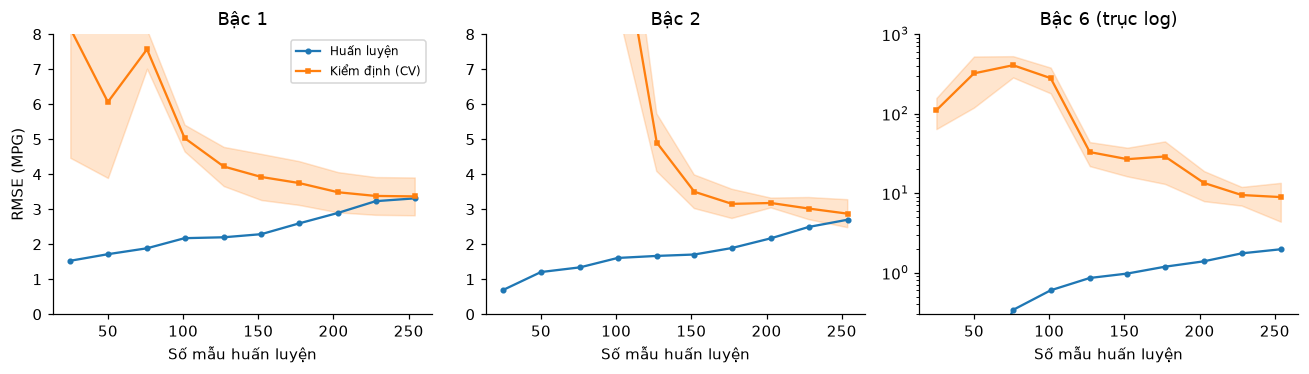

,Bậc,Số mẫu,RMSE huấn luyện,RMSE CV
0,1,25,1.53,8.16
4,1,127,2.20,4.22
9,1,254,3.31,3.37
10,2,25,0.70,47.90
14,2,127,1.67,4.90
19,2,254,2.70,2.87
20,6,25,0.00,110.56
24,6,127,0.86,32.87
29,6,254,1.97,8.93


In [2]:
sizes = np.linspace(0.1, 1.0, 10)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
lc_rows = []
for a, d in zip(ax, [1, 2, 6]):
    n, tr, va = learning_curve(poly(d), X4, y, cv=folds, train_sizes=sizes, scoring="neg_root_mean_squared_error")
    tr, va = -tr, -va
    a.plot(n, tr.mean(1), "o-", ms=3, label="Huấn luyện")
    a.fill_between(n, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2, color="C1")
    a.plot(n, va.mean(1), "s-", ms=3, label="Kiểm định (CV)")
    a.set_title(f"Bậc {d}" + (" (trục log)" if d == 6 else "")); a.set_xlabel("Số mẫu huấn luyện")
    if d == 6: a.set_yscale("log"); a.set_ylim(0.3, 1000)   # RMSE kiểm định bậc 6 lên tới hàng trăm
    else: a.set_ylim(0, 8)
    for ni, t, v in zip(n, tr.mean(1), va.mean(1)):
        lc_rows.append({"Bậc": d, "Số mẫu": ni, "RMSE huấn luyện": t, "RMSE CV": v})
ax[0].set_ylabel("RMSE (MPG)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_5_learning_curve.png", bbox_inches="tight"); plt.show()
lc = pd.DataFrame(lc_rows)
lc[lc.groupby("Bậc").cumcount().isin([0, 4, 9])].round(2)

**Nhận xét.**
- **Bậc 1 – high bias (underfitting):** với 254 mẫu, RMSE huấn luyện 3,31 và kiểm định 3,37 gần như trùng nhau; đường kiểm định đã đi ngang từ khoảng 200 mẫu (3,48 → 3,38 → 3,37). Thêm dữ liệu gần như không giúp ích, cần mô hình phức tạp hơn.
- **Bậc 2 – cân bằng:** RMSE huấn luyện 2,70, kiểm định 2,87, khoảng cách 0,17; đường kiểm định vẫn còn giảm nhẹ (3,18 ở 203 mẫu, 3,02 ở 228, 2,87 ở 254), nên có thêm dữ liệu thì mô hình có thể còn tốt hơn chút ít. Với ít hơn khoảng 130 mẫu, bậc 2 lại overfit nặng (RMSE kiểm định 11–57), tức độ phức tạp phù hợp phụ thuộc vào kích thước dữ liệu.
- **Bậc 6 – high variance (overfitting):** RMSE huấn luyện chỉ 0–2 nhưng kiểm định 8,93 ở 254 mẫu (lên tới 407 ở 76 mẫu). Khoảng cách thu hẹp khi thêm dữ liệu nhưng còn rất xa; muốn dùng bậc 6 phải điều chuẩn (Ridge) hoặc có nhiều dữ liệu hơn hẳn.

## 2. Ước lượng bias² và variance bằng bootstrap
Tách một lần phần huấn luyện theo fold đầu tiên: 254 mẫu để lấy mẫu bootstrap, 64 mẫu làm tập đánh giá (vẫn nằm trong tập huấn luyện, không đụng tập kiểm tra).
Với B = 200 lần: lấy mẫu có hoàn lại 254 mẫu, huấn luyện lại, dự đoán 64 mẫu đánh giá. Theo mục 1.2.2, **bias² ước lượng ở đây gồm cả nhiễu σ²** vì so với y quan sát.

In [3]:
B = 200
tr_idx, ev_idx = folds[0]
Xb_src, yb_src = X4.iloc[tr_idx], y.iloc[tr_idx].to_numpy()
X_ev, y_ev = X4.iloc[ev_idx], y.iloc[ev_idx].to_numpy()

def bias_variance(model, X_src=Xb_src, X_eval=X_ev):
    rng = np.random.default_rng(SEED)
    preds = np.empty((B, len(y_ev)))
    for b in range(B):
        i = rng.integers(0, len(yb_src), len(yb_src))
        preds[b] = clone(model).fit(X_src.iloc[i], yb_src[i]).predict(X_eval)
    bias2 = np.mean((preds.mean(0) - y_ev) ** 2)
    var = np.mean(preds.var(0))
    return {"Bias² (gồm nhiễu)": bias2, "Variance": var, "Tổng (≈ MSE)": bias2 + var}

bv = pd.DataFrame({d: bias_variance(poly(d)) for d in range(1, 11)}).T
bv.index.name = "Bậc"
bv.round(2)

,Bias² (gồm nhiễu),Variance,Tổng (≈ MSE)
Bậc,,,
1,8.46,0.35,8.82
2,6.48,0.66,7.14
3,4.86,2.63,7.48
4,18.15,19.27,37.42
5,10.27,60.66,70.93
6,9.25,129.90,139.15
7,23.78,320.58,344.36
8,58.02,640.70,698.71
9,157.63,1483.87,1641.51


In [4]:
bv_ridge = pd.DataFrame({
    "Bậc 2, không điều chuẩn": bias_variance(poly(2)),
    "Bậc 6, không điều chuẩn": bias_variance(poly(6)),
    "Bậc 6, Ridge α = 10": bias_variance(make_pipeline(build_preprocessor(POLY, CAT, 6), Ridge(alpha=10))),
    "Bậc 10, Ridge α = 31,6": bias_variance(make_pipeline(build_preprocessor(POLY, CAT, 10), Ridge(alpha=31.6))),
    "KNN k = 1": bias_variance(make_pipeline(build_preprocessor(), KNeighborsRegressor(1)), X7.iloc[tr_idx], X7.iloc[ev_idx]),
    "KNN k = 3": bias_variance(make_pipeline(build_preprocessor(), KNeighborsRegressor(3)), X7.iloc[tr_idx], X7.iloc[ev_idx]),
    "KNN k = 20": bias_variance(make_pipeline(build_preprocessor(), KNeighborsRegressor(20)), X7.iloc[tr_idx], X7.iloc[ev_idx]),
}).T
pd.concat([bv.rename(index=lambda d: f"Bậc {d}"), bv_ridge]).to_csv(REP / "bang_bias_variance.csv")
bv_ridge.round(2)

,Bias² (gồm nhiễu),Variance,Tổng (≈ MSE)
"Bậc 2, không điều chuẩn",6.48,0.66,7.14
"Bậc 6, không điều chuẩn",9.25,129.90,139.15
"Bậc 6, Ridge α = 10",6.20,0.41,6.61
"Bậc 10, Ridge α = 31,6",5.97,0.46,6.43
KNN k = 1,7.42,4.66,12.08
KNN k = 3,5.36,3.40,8.75
KNN k = 20,7.41,0.80,8.20


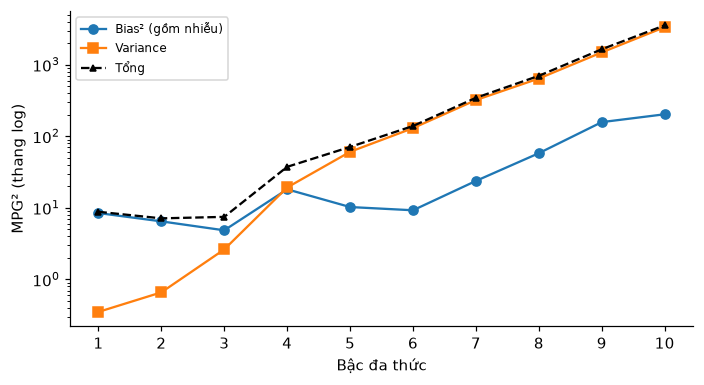

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(bv.index, bv["Bias² (gồm nhiễu)"], "o-", label="Bias² (gồm nhiễu)")
ax.plot(bv.index, bv["Variance"], "s-", label="Variance")
ax.plot(bv.index, bv["Tổng (≈ MSE)"], "k^--", ms=4, label="Tổng")
ax.set_yscale("log"); ax.set_xticks(range(1, 11))
ax.set_xlabel("Bậc đa thức"); ax.set_ylabel("MPG² (thang log)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_6_bias_variance.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Bias² (gồm nhiễu) giảm từ 8,46 (bậc 1) xuống 4,86 (bậc 3), trong khi variance tăng từ 0,35 lên 2,63 rồi bùng nổ tới 3342 ở bậc 10. Tổng nhỏ nhất ở **bậc 2** (7,14), sát bậc 3 (7,48), khớp với kết luận từ CV ở notebook 03. Từ bậc 4 cả bias² cũng tăng lại: các dự đoán bậc cao dao động mạnh ở các xe nằm rìa miền dữ liệu, trung bình của chúng không triệt tiêu về giá trị đúng.

Ridge làm giảm variance mạnh mà bias² không tăng: ở bậc 6, α = 10 đưa variance từ 129,90 xuống 0,41 và bias² từ 9,25 xuống 6,20; Ridge bậc 10 (α = 31,6) có tổng nhỏ nhất bảng (6,43). Với KNN, k = 1 có variance 4,66; k = 20 giảm variance còn 0,80 nhưng bias² tăng lên 7,41; k = 3 có bias² thấp nhất (5,36) nhưng variance 3,40. Đây đúng là hình ảnh đánh đổi bias–variance ở mục 1.2.2.

Lưu ý khi đọc: bias² ở đây gồm cả nhiễu σ² nên không thể về 0, và tập đánh giá chỉ có 64 mẫu, nên các giá trị chỉ dùng để so sánh tương đối giữa các mô hình.

## 3. Phân tích lỗi theo nhóm xe
Dùng dự đoán ngoài fold của hai mô hình: tuyến tính 7 đặc trưng (baseline) và Ridge bậc 6, α = 10 (tốt nhất ở notebook 03).

In [6]:
m_lin = make_pipeline(build_preprocessor(), LinearRegression())
m_ridge = make_pipeline(build_preprocessor(POLY, CAT, 6), Ridge(alpha=10))
loi = train[["name", "origin", "cylinders", "weight", "model_year", "mpg"]].copy()
loi["du_doan_tt"] = cross_val_predict(m_lin, X7, y, cv=folds)
loi["du_doan_ridge"] = cross_val_predict(m_ridge, X4, y, cv=folds)
loi["loi_tt"], loi["loi_ridge"] = loi["mpg"] - loi["du_doan_tt"], loi["mpg"] - loi["du_doan_ridge"]
loi["nhom_kl"] = pd.cut(loi["weight"], [0, 2200, 2800, 3500, 6000], labels=["< 2200", "2200–2800", "2800–3500", "≥ 3500"])
loi["nhom_nam"] = pd.cut(loi["model_year"], [69, 73, 76, 79, 82], labels=["1970–73", "1974–76", "1977–79", "1980–82"])

def theo_nhom(cot):
    g = loi.groupby(cot, observed=True)
    return pd.DataFrame({"Số mẫu": g.size(),
                         "RMSE tuyến tính": g["loi_tt"].apply(lambda e: np.sqrt((e ** 2).mean())),
                         "RMSE Ridge": g["loi_ridge"].apply(lambda e: np.sqrt((e ** 2).mean())),
                         "Lỗi TB Ridge (thực − dự đoán)": g["loi_ridge"].mean()})

nhom = pd.concat({"Xuất xứ": theo_nhom("origin"), "Số xi-lanh": theo_nhom("cylinders"),
                  "Khối lượng (lb)": theo_nhom("nhom_kl"), "Năm sản xuất": theo_nhom("nhom_nam")})
nhom.to_csv(REP / "bang_loi_theo_nhom.csv")
nhom.round(2)

Số mẫu  RMSE tuyến tính  RMSE Ridge  \
Xuất xứ         europe         56             4.40        3.64   
                japan          63             3.67        3.50   
                usa           199             2.90        2.34   
Số xi-lanh      3               3             6.74        6.51   
                4             158             3.50        3.12   
                5               2             7.53        6.22   
                6              66             3.51        2.92   
                8              89             2.61        1.84   
Khối lượng (lb) < 2200         68             4.10        3.62   
                2200–2800      85             3.16        2.96   
                2800–3500      75             3.88        3.11   
                ≥ 3500         90             2.31        1.64   
Năm sản xuất    1970–73        99             2.78        2.29   
                1974–76        74             2.81        2.08   
                1977–79        72             3.43        2.63   
                1980–82        73             4.38        4.17   

                           Lỗi TB Ridge (thực − dự đoán)  
Xuất xứ         europe                              0.20  
                japan                               0.02  
                usa                                -0.07  
Số xi-lanh      3                                  -6.35  
                4                                   0.21  
                5                                   1.68  
                6                                  -0.38  
                8                                   0.08  
Khối lượng (lb) < 2200                              0.33  
                2200–2800                           0.10  
                2800–3500                          -0.69  
                ≥ 3500                              0.22  
Năm sản xuất    1970–73                            -0.11  
                1974–76                            -0.30  
                1977–79                             0.08  
                1980–82                             0.37

In [7]:
print("10 mẫu Ridge dự đoán sai nhiều nhất:")
loi.reindex(loi["loi_ridge"].abs().sort_values(ascending=False).index)[
    ["name", "origin", "cylinders", "weight", "model_year", "mpg", "du_doan_ridge", "loi_ridge"]].head(10).round(1)

10 mẫu Ridge dự đoán sai nhiều nhất:


,name,origin,cylinders,weight,model_year,mpg,du_doan_ridge,loi_ridge
254,mazda glc,japan,4,2110,80,46.6,34.5,12.1
308,oldsmobile cutlass ciera (diesel),usa,6,3015,82,38.0,26.8,11.2
245,vw rabbit,europe,4,2144,80,41.5,33.1,8.4
89,maxda rx3,japan,3,2124,73,18.0,26.2,-8.2
263,datsun 280-zx,japan,6,2910,80,32.7,24.7,8.0
260,renault lecar deluxe,europe,4,1835,80,40.9,33.0,7.9
252,datsun 510 hatchback,japan,4,2434,80,37.0,29.2,7.8
258,audi 5000s (diesel),europe,5,2950,80,36.4,28.7,7.7
301,mazda glc custom,japan,4,1970,82,31.0,38.5,-7.5
244,pontiac phoenix,usa,4,2556,79,33.5,26.5,7.0


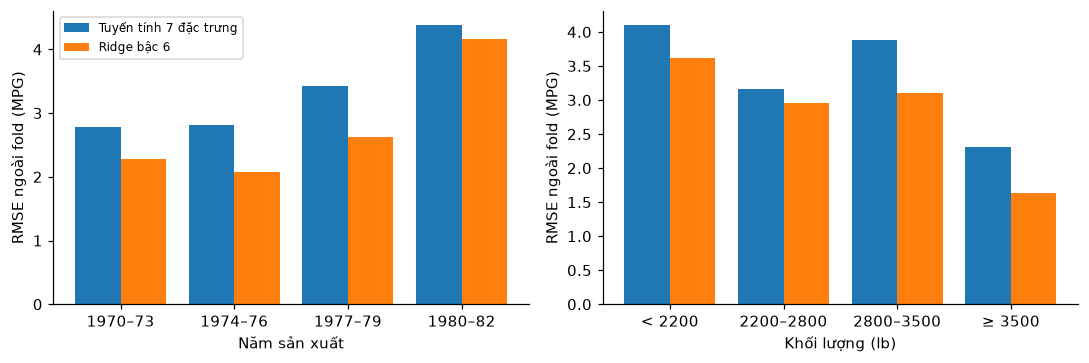

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, cot, ten in [(ax[0], "nhom_nam", "Năm sản xuất"), (ax[1], "nhom_kl", "Khối lượng (lb)")]:
    t = theo_nhom(cot)
    x = np.arange(len(t))
    a.bar(x - .2, t["RMSE tuyến tính"], .4, label="Tuyến tính 7 đặc trưng")
    a.bar(x + .2, t["RMSE Ridge"], .4, label="Ridge bậc 6")
    a.set_xticks(x, t.index.astype(str)); a.set_xlabel(ten); a.set_ylabel("RMSE ngoài fold (MPG)")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_7_loi_theo_nhom.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Ridge bậc 6 giảm lỗi so với baseline tuyến tính ở mọi nhóm, nhưng lỗi vẫn tập trung ở một số nhóm:
- **Xe đời mới 1980–82:** RMSE 4,17, cao gần gấp đôi các nhóm năm khác (2,08–2,63). Đây là giai đoạn sau khủng hoảng dầu mỏ, xe tiết kiệm hơn hẳn nhờ công nghệ mà các đặc trưng hiện có không mô tả hết.
- **Xe nhẹ (< 2200 lb):** RMSE 3,62, so với 1,64 ở xe ≥ 3500 lb. Xe nhẹ có MPG cao và phân tán rộng nên sai số tuyệt đối lớn hơn.
- **Xe châu Âu và Nhật:** RMSE 3,64 và 3,50, so với 2,34 ở xe Mỹ (199 mẫu): ít mẫu hơn và đa dạng hơn.
- **Nhóm 3 và 5 xi-lanh:** chỉ 3 và 2 mẫu, RMSE trên 6. Nhóm 3 xi-lanh bị dự đoán cao trung bình 6,35 MPG: đó là các xe Mazda động cơ quay (rotary, ví dụ "maxda rx3" 18 MPG, dự đoán 26,2), tốn xăng hơn nhiều so với một động cơ 3 xi-lanh thông thường.
- **Xe diesel:** 2 trong 10 mẫu sai nhất là xe diesel (oldsmobile cutlass ciera diesel sai 11,2 MPG, audi 5000s diesel sai 7,7 MPG), bị dự đoán thấp vì dữ liệu không có cột loại nhiên liệu.

Phần lớn các lỗi lớn đến từ thông tin **không có trong các đặc trưng** (loại nhiên liệu, loại động cơ, công nghệ thời kỳ sau 1980), chứ không phải do mô hình quá đơn giản. So sánh lỗi huấn luyện với kiểm định (notebook 03: Ridge bậc 6 có 2,67 so với 2,83) cho thấy mô hình không còn quá khớp đáng kể.

## 4. Đặc trưng nào ảnh hưởng nhiều đến dự đoán?
(a) Hệ số của hồi quy tuyến tính trên đặc trưng đã chuẩn hóa (cùng thang đo nên so sánh được độ lớn).
(b) Permutation importance: xáo trộn một cột trên **phần kiểm định** của từng fold và đo RMSE tăng bao nhiêu; lấy trung bình 5 fold.

In [9]:
m = m_lin.fit(X7, y)
he_so = pd.Series(m[-1].coef_, index=[n.split("__")[1] for n in m[0].get_feature_names_out()]).sort_values(key=abs, ascending=False)
print("Hệ số chuẩn hóa của hồi quy tuyến tính (MPG trên 1 độ lệch chuẩn):"); print(he_so.round(2).to_string())

def perm(model, X):
    out = []
    for tr, va in folds:
        f = clone(model).fit(X.iloc[tr], y.iloc[tr])
        r = permutation_importance(f, X.iloc[va], y.iloc[va], scoring="neg_root_mean_squared_error", n_repeats=20, random_state=SEED)
        out.append(r.importances_mean)
    return pd.Series(np.mean(out, 0), index=X.columns)

pi = pd.DataFrame({"Tuyến tính 7 đặc trưng": perm(m_lin, X7), "Ridge bậc 6 (4 đặc trưng + origin)": perm(m_ridge, X4)})
pi.to_csv(REP / "bang_permutation_importance.csv")
pi.sort_values("Tuyến tính 7 đặc trưng", ascending=False).round(2)

Hệ số chuẩn hóa của hồi quy tuyến tính (MPG trên 1 độ lệch chuẩn):
weight          -5.86
model_year       3.03
displacement     2.90
origin_usa      -2.08
origin_europe    1.26
cylinders       -0.96
origin_japan     0.81
acceleration     0.51
horsepower      -0.42


,Tuyến tính 7 đặc trưng,Ridge bậc 6 (4 đặc trưng + origin)
weight,5.53,3.30
model_year,2.08,2.26
displacement,1.92,NaN
origin,0.59,0.14
cylinders,0.25,NaN
acceleration,0.08,0.40
horsepower,0.04,1.82


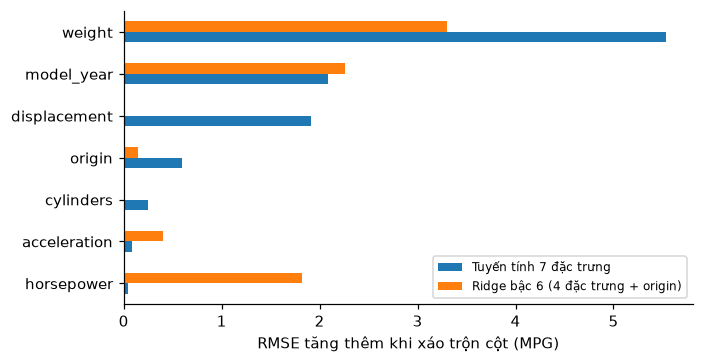

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
pi.sort_values("Tuyến tính 7 đặc trưng").plot.barh(ax=ax)
ax.set_xlabel("RMSE tăng thêm khi xáo trộn cột (MPG)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_8_permutation_importance.png", bbox_inches="tight"); plt.show()

**Nhận xét.**
- `weight` quan trọng nhất ở cả hai mô hình: xáo trộn cột này làm RMSE tăng 5,53 (tuyến tính) và 3,30 (Ridge). `model_year` đứng thứ hai (2,08 và 2,26), phản ánh tiến bộ công nghệ qua các năm.
- Trong mô hình tuyến tính, `displacement` có hệ số **dương** (+2,90) dù tương quan với MPG là −0,80. Đây là hệ quả của đa cộng tuyến với `weight` (VIF cao, mục 2.2.3): hệ số chỉ thể hiện tác động khi giữ các biến khác cố định, nên không diễn giải riêng lẻ được.
- `horsepower` gần như vô dụng trong mô hình tuyến tính (0,04) nhưng quan trọng thứ ba trong Ridge bậc 6 (1,82). Tác động của công suất là phi tuyến và qua tương tác với khối lượng, mô hình tuyến tính không dùng được; mô hình đa thức có các số hạng như horsepower² và horsepower × weight nên khai thác được.
- `origin` ảnh hưởng nhỏ (0,59 và 0,14) khi đã biết khối lượng: phần lớn chênh lệch MPG giữa xe Mỹ và xe Nhật/châu Âu (Hình 2.6) là do xe Mỹ nặng hơn.

Điều này giải thích vì sao Ridge bậc 6 tốt hơn mô hình tuyến tính: nó tận dụng được độ cong và tương tác của `weight` và `horsepower`.